# 03 — Head-size normalization, then a batch

**The problem this notebook solves.** Notebook 02 gave you IXI002's region volumes in mL. But a big head has big regions without being an old head. To compare subjects fairly you need each subject's **intracranial volume (ICV)** — the size of the container — and to express regions relative to it.

**Where ICV comes from.** You already own the tool: the affine registration. Its linear part *scales* the subject onto the template. That scaling's determinant is a volume ratio, so ICV_subject = (template brain volume) / |det|. One registration gives you both the atlas warp *and* the head size.

**Plan:** (1) measure the template's brain-mask volume, (2) re-register IXI002 and extract its determinant -> ICV, (3) normalize IXI002's regions, (4) wrap the whole pipeline in a function, (5) run it on 8 subjects spread across the age range, (6) plot volume-vs-age and ICV-vs-age and read what they say.

Notebooks must run top-to-bottom on a fresh kernel, so this one re-does a few notebook-02 steps rather than assuming their variables still exist.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from pathlib import Path
import ants
from nilearn import datasets
import scipy.io

subjects_df = pd.read_csv('subjects.csv')
atlas = datasets.fetch_atlas_harvard_oxford('cort-maxprob-thr25-2mm')
labels = atlas.labels



[fetch_atlas_harvard_oxford] Dataset directory found: /Users/jacobruss/nilearn_data/fsl


In [ ]:
template_mask = datasets.load_mni152_brain_mask(resolution=2)
template_mask_data = template_mask.get_fdata()
nonzero_voxels = np.sum(template_mask_data > 0)
template_icv_ml = nonzero_voxels * 8 / 1000


In [ ]:
template = datasets.load_mni152_template(resolution=2)
nib.save(template, "data/mni152_template_2mm.nii.gz")
template_ants = ants.image_read("data/mni152_template_2mm.nii.gz")
subject_ants = ants.image_read("data/IXI-T1/IXI002-Guys-0828-T1.nii.gz")
reg = ants.registration(fixed=template_ants, moving=subject_ants, type_of_transform='Affine')


# ICV by mask propagation: warp the template's brain mask into
# the subject with the SAME registration, then measure it there.
nib.save(template_mask, "data/mni152_brain_mask_2mm.nii.gz")
mask_ants = ants.image_read("data/mni152_brain_mask_2mm.nii.gz")

mask_warped = ants.apply_transforms(fixed=subject_ants, moving=mask_ants,transformlist=reg['invtransforms'],interpolator='genericLabel')

voxel_volume_ml = np.prod(subject_ants.spacing) / 1000
icv_ml = np.sum(mask_warped.numpy() > 0) * voxel_volume_ml
print("ICV (mL):", icv_ml)



ICV (mL): 1327.4695537492632


In [19]:
# STEP 4 - Normalize IXI002
atlas_ants = ants.image_read("data/harvard_oxford_atlas.nii.gz")
warped_atlas = ants.apply_transforms(fixed=subject_ants, moving=atlas_ants,transformlist=reg['invtransforms'], interpolator='genericLabel')

voxel_volume_mm3 = np.prod(subject_ants.spacing)  # Voxel volume in mm^3
warped_arr = warped_atlas.numpy()  # Convert ANTs image to numpy array (once)

region_volumes = []
for region_id in range(1, len(labels)):  # Skip background (0)
    voxel_count = np.sum(warped_arr == region_id)
    volume_ml = (voxel_count * voxel_volume_mm3) / 1000  # Convert to mL
    region_volumes.append((labels[region_id], volume_ml))

# Sort by volume in descending order
region_volumes.sort(key=lambda x: x[1], reverse=True)

# Table with head-size-normalized fractions
volumes_df = pd.DataFrame(region_volumes, columns=['region', 'volume_ml'])
volumes_df['fraction'] = volumes_df['volume_ml'] / icv_ml
print(volumes_df.head(10))


                                        region  volume_ml  fraction
0                                 Frontal Pole  87.069505  0.065591
1  Lateral Occipital Cortex, superior division  55.034508  0.041458
2                             Precentral Gyrus  48.318276  0.036399
3                            Postcentral Gyrus  38.904159  0.029307
4                            Precuneous Cortex  31.868356  0.024007
5                         Middle Frontal Gyrus  30.102814  0.022677
6                               Occipital Pole  29.332894  0.022097
7                       Superior Frontal Gyrus  28.588287  0.021536
8                                Temporal Pole  26.478917  0.019947
9  Lateral Occipital Cortex, inferior division  23.042754  0.017358


## From one subject to a function

Steps 2–4 work, but they're a pile of loose cells. Before running 8 subjects — let alone 563 — the pipeline becomes **one function**: file path in, measurements out. Everything after this point calls the function; nobody copy-pastes cells per subject. This is also the shape the eventual batch script will take.

In [21]:
def process_subject(path):
    # Stage 1: load the subject
    subject_ants = ants.image_read(path)

    # Stage 2: register it to the template
    reg = ants.registration(fixed=template_ants, moving=subject_ants,type_of_transform='Affine')

    voxel_volume_mm3 = np.prod(subject_ants.spacing)

    # Stage 3: warp the atlas in, count region volumes
    warped_atlas = ants.apply_transforms(fixed=subject_ants, moving=atlas_ants,transformlist=reg['invtransforms'],interpolator='genericLabel')
    warped_arr = warped_atlas.numpy()

    region_volumes = {}
    for region_id in range(1, len(labels)):  # Skip background (0)
        voxel_count = np.sum(warped_arr == region_id)
        volume_ml = (voxel_count * voxel_volume_mm3) / 1000
        region_volumes[labels[region_id]] = volume_ml

    # Stage 4: ICV - warp the brain mask in with the SAME registration
    mask_warped = ants.apply_transforms(fixed=subject_ants, moving=mask_ants,transformlist=reg['invtransforms'],interpolator='genericLabel')
    icv_ml = np.sum(mask_warped.numpy() > 0) * voxel_volume_mm3 / 1000

    # Stage 5: assemble and return
    result_dict = {'icv_ml': icv_ml}
    result_dict.update(region_volumes)
    return result_dict

result = process_subject("data/IXI-T1/IXI002-Guys-0828-T1.nii.gz")
print(result['icv_ml'], result['Frontal Pole'] / result['icv_ml'])


1118.3076247394085 0.06543471618109181


In [22]:
# STEP 6 - Pick 8 subjects across the age range, then run
# Choosing the batch: from your subjects DataFrame, drop the
# rows with missing age, sort by age, and pick 8 rows at
# evenly spaced positions (np.linspace(0, n-1, 8) cast to
# int gives the positions). You want the youngest, the
# oldest, and six in between - NOT the first 8 rows, which
# are just the lowest subject IDs in arbitrary age order.
# Running: loop over the chosen rows; for each, build its
# file path (data/IXI-T1 + the file column), call
# process_subject, and collect the dicts - adding 'subject'
# and 'age' to each. Print one progress line per subject
# (subject, age, ICV) with flush=True so you can watch it
# work; expect several minutes total for 8 subjects.
# WATCH the ICVs as they print: all should land 1,200-1,800.
# A wild value (700, 2,600) means THAT subject's registration
# failed and its row is poison - note which one; don't let
# it silently into the results.
# Finally: assemble a DataFrame (one row per subject) and
# save it as regional_volumes_batch.csv.

# Pick 8 subjects across the age range
subjects_df = subjects_df.dropna(subset=['age'])
subjects_df = subjects_df.sort_values(by='age')
num_subjects = len(subjects_df)
selected_indices = np.linspace(0, num_subjects - 1, 8, dtype=int)
selected_subjects = subjects_df.iloc[selected_indices]

results = []

for _, row in selected_subjects.iterrows():
    subject_id = row['subject']
    age = row['age']
    file_path = f"data/IXI-T1/{row['file']}"
    result_dict = process_subject(file_path)
    result_dict['subject'] = subject_id
    result_dict['age'] = age
    print(f"Processed {subject_id}, age {age}, ICV: {result_dict['icv_ml']:.2f} mL", flush=True)
    results.append(result_dict)

batch_df = pd.DataFrame(results)
batch_df.to_csv('regional_volumes_batch.csv', index=False)
print(batch_df.shape)

Processed IXI425, age 19.980835044490075, ICV: 1218.90 mL
Processed IXI078, age 28.50650239561944, ICV: 1078.55 mL
Processed IXI601, age 35.51540041067762, ICV: 1136.80 mL
Processed IXI191, age 44.205338809034906, ICV: 972.53 mL
Processed IXI367, age 54.21492128678987, ICV: 1298.75 mL
Processed IXI495, age 60.86789869952088, ICV: 944.28 mL
Processed IXI326, age 67.73990417522245, ICV: 1865.39 mL
Processed IXI464, age 86.3189596167009, ICV: 1054.55 mL
(8, 51)


In [23]:
batch_df.to_csv('regional_volumes_batch.csv', index=False)

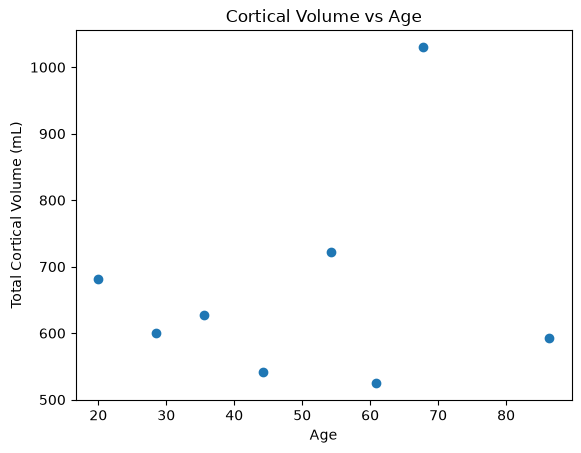

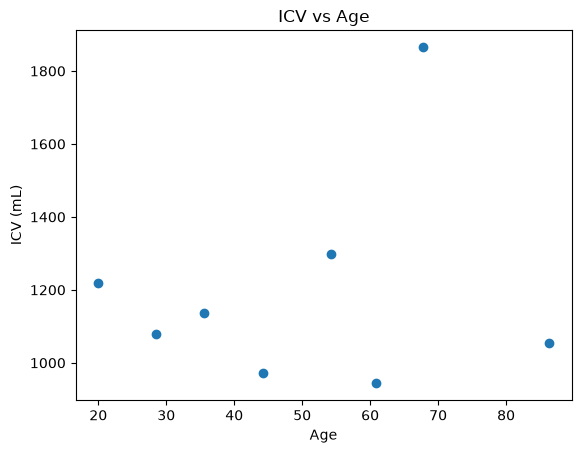

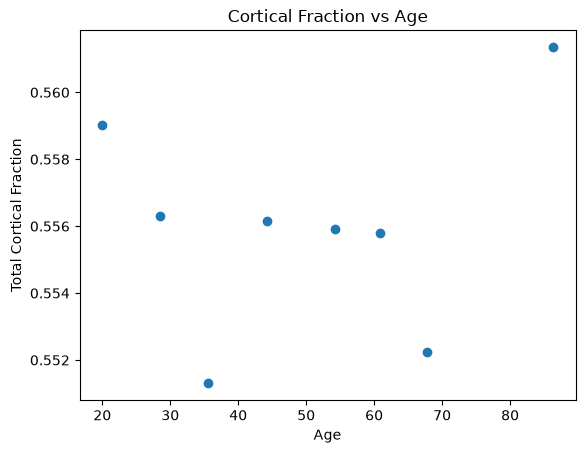

In [26]:
# STEP 7 - Read the batch
# Two scatter plots (matplotlib plt.scatter), age on x:
#   (a) total cortical volume per subject (sum the 48 region
#       columns of your batch DataFrame) vs age.
#   (b) icv_ml vs age.
# What to look for:
#   - (a) should drift gently DOWNWARD with age: cortices
#     thin over a lifetime. With 8 subjects and an affine-
#     only method it'll be noisy - a rough downward drift
#     is all you ask of it.
#   - (b) should be a FLAT cloud. Skull size is fixed by
#     early adulthood; ICV must NOT grow or shrink with
#     age. If (b) trends, your ICV estimates are absorbing
#     something they shouldn't.
# Bonus if both look right: pick one region and plot its
# FRACTION (region / icv) vs age.

region_cols = list(labels[1:])  # the 48 region names, exactly
batch_df['total_ml'] = batch_df[region_cols].sum(axis=1)
batch_df['total_fraction'] = batch_df['total_ml'] / batch_df['icv_ml']


plt.scatter(batch_df['age'], batch_df['total_ml'])
plt.xlabel('Age')
plt.ylabel('Total Cortical Volume (mL)')
plt.title('Cortical Volume vs Age')
plt.show()

plt.scatter(batch_df['age'], batch_df['icv_ml'])
plt.xlabel('Age')
plt.ylabel('ICV (mL)')
plt.title('ICV vs Age')
plt.show()

plt.scatter(batch_df['age'], batch_df['total_fraction'])
plt.xlabel('Age')
plt.ylabel('Total Cortical Fraction')
plt.title('Cortical Fraction vs Age')
plt.show()



In [27]:
batch_df.to_csv('regional_volumes_batch.csv', index=False)